# Appendix

Extra checks. Takes about 15 to 20 minutes and does not change the main results.

- A.1 what the convergence rule does and does not guarantee
- A.2 fast and simple evaluators give the same results
- A.3 why seed 104 fails at 40%
- A.4 the synthetic data

In [1]:
import csv
import json
import sys
import time
from pathlib import Path
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

root = Path.cwd()
if not (root / 'data_shapley').is_dir():
    root = root.parent
sys.path.insert(0, str(root))

from data_shapley.data import (make_data_rngs, load_penguins, split_penguins,
    standardize_split, generate_gaussian_split, corrupt_training_labels, CLASS_LABELS)
from data_shapley.shapley import (SortedKNNGame, make_knn_utility, evaluate_permutations_naive)
from data_shapley.metrics import rank_agreement, bottom_overlap, ranking_order, average_ranks


def table(headers, rows):
    head = ''.join('<th>' + escape(str(x)) + '</th>' for x in headers)
    body = ''.join('<tr>' + ''.join('<td>' + escape(str(x)) + '</td>' for x in row) + '</tr>' for row in rows)
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'))

plt.rcParams.update({'figure.figsize': (8, 3.6), 'font.size': 11})
rngs, _ = make_data_rngs(100)
penguins, _ = standardize_split(split_penguins(load_penguins(root/'data/raw/penguins.csv'), rngs['penguins_split']))
gaussian, _ = standardize_split(generate_gaussian_split(rngs['synthetic_train'], rngs['synthetic_validation'], rngs['synthetic_test']))
penguin_noise = corrupt_training_labels(penguins.train, 41, CLASS_LABELS, rngs['penguins_noise'])
gaussian_noise = corrupt_training_labels(gaussian.train, 30, (0, 1), rngs['synthetic_noise'])
conditions = [('clean_penguins', penguins, penguins.train.y),
              ('noisy_penguins', penguins, penguin_noise.training.y),
              ('noisy_gaussian', gaussian, gaussian_noise.training.y)]

## A.1 Convergence rule and ranking stability

The study stops each run with the [rule of Ghorbani & Zou (2019)](https://proceedings.mlr.press/v97/ghorbani19c/ghorbani19c.pdf): the average relative change of the values over the last 100 permutations must be below 0.05 (zero values are skipped).

Here we draw two new 6000-permutation runs for clean Penguins, seed 100, and compare their rankings as they grow.

In [2]:
def change_rules(current, previous, exact_total):
    """The paper's rule and a total-change diagnostic. Zero estimates are found from exact
    integer totals of correct-count changes, as in the study."""
    delta = np.abs(current - previous)
    magnitude = np.abs(current)
    keep = exact_total != 0
    paper_rule = float(np.mean(delta[keep] / magnitude[keep])) if keep.any() else np.nan
    total_rule = float(delta.sum() / magnitude.sum()) if keep.any() else np.nan
    return paper_rule, total_rule, int((~keep).sum())

In [3]:
game = SortedKNNGame(penguins.train.X, penguins.train.y, penguins.validation.X,
                     penguins.validation.y, penguins.train.y)
n = len(penguins.train.y)
priority = np.random.default_rng(np.random.SeedSequence(100, spawn_key=(9, 0))).permutation(n)
checkpoints = (500, 1000, 2000, 4000, 6000)
estimates, rules = {}, {}
near_zero = None
for stream in (0, 1):
    rng = np.random.default_rng(np.random.SeedSequence(100, spawn_key=(20, stream)))
    cumulative = np.zeros(n)
    count_changes = np.zeros(n, dtype=np.int64)
    for m in range(100, 6001, 100):
        previous = cumulative.copy() / (m - 100) if m > 100 else None
        batch = game.sample(100, rng).marginals
        cumulative += batch.sum(0)
        count_changes += np.rint(batch * len(penguins.validation.y)).astype(np.int64).sum(0)
        if m in checkpoints:
            current = cumulative / m
            estimates[stream, m] = current.copy()
            rules[stream, m] = change_rules(current, previous, count_changes)
            print(f'Stream {stream}: {m}/6000 permutations', flush=True)
            if stream == 0 and m == 500:
                ratios = np.divide(np.abs(current-previous), np.abs(current),
                                   out=np.zeros(n), where=current != 0)
                i = int(np.argmax(ratios))
                near_zero = [stream, m, int(penguins.train.observation_ids[i]),
                             f'{current[i]:.3e}', f'{previous[i]:.6f}', int(count_changes[i])]

stability = []
for m in checkpoints:
    a, b = estimates[0, m], estimates[1, m]
    overlap = bottom_overlap(a, b, penguins.train.observation_ids, .2, priority)
    stability.append([m, rank_agreement(a, b)['spearman'], overlap['shared'], overlap['count']])
table(['M', 'Spearman', 'Shared bottom points', 'Paper rule: 0', 'Paper rule: 1', 'Both below 0.05?'],
      [[m, f'{rho:.3f}', f'{shared}/{count}', f'{rules[0,m][0]:.4g}', f'{rules[1,m][0]:.4g}',
        all(rules[s,m][0] < .05 for s in (0,1))] for m, rho, shared, count in stability])
table(['Stream', 'M', 'Paper rule', 'Total change', 'Skipped'],
      [[s, m, f'{rules[s,m][0]:.4g}', f'{rules[s,m][1]:.4f}', rules[s,m][2]]
       for s in (0,1) for m in checkpoints])

Stream 0: 500/6000 permutations


Stream 0: 1000/6000 permutations


Stream 0: 2000/6000 permutations


Stream 0: 4000/6000 permutations


Stream 0: 6000/6000 permutations


Stream 1: 500/6000 permutations


... (2 outputs left out)

Stream 1: 4000/6000 permutations


Stream 1: 6000/6000 permutations


M,Spearman,Shared bottom points,Paper rule: 0,Paper rule: 1,Both below 0.05?
500,0.206,11/41,0.5366,0.6612,False
1000,0.222,14/41,0.3072,0.3452,False
2000,0.438,17/41,0.1859,0.08451,False
4000,0.605,26/41,0.05149,0.09079,False
6000,0.656,31/41,0.03318,0.0294,True


Stream,M,Paper rule,Total change,Skipped
0,500,0.5366,0.2683,3
0,1000,0.3072,0.1283,0
0,2000,0.1859,0.0646,0
0,4000,0.05149,0.0311,0
0,6000,0.03318,0.0202,0
1,500,0.6612,0.2677,0
1,1000,0.3452,0.1209,0
1,2000,0.08451,0.0543,0
1,4000,0.09079,0.0310,0
1,6000,0.0294,0.0206,0


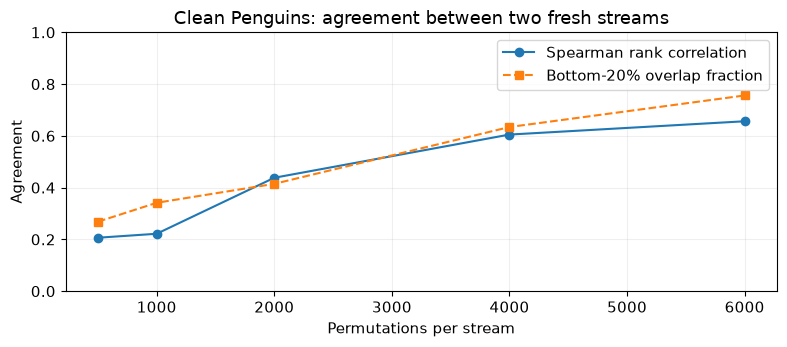

Stream,M,Observation ID,Current estimate,Previous estimate,Integer contribution sum
0,500,340,1.110e-19,0.000772,0


In [4]:
fig, ax = plt.subplots()
ax.plot([r[0] for r in stability], [r[1] for r in stability], 'o-', label='Spearman rank correlation')
ax.plot([r[0] for r in stability], [r[2]/r[3] for r in stability], 's--', label='Bottom-20% overlap fraction')
ax.set(xlabel='Permutations per stream', ylabel='Agreement', ylim=(0, 1),
       title='Clean Penguins: agreement between two fresh streams')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
plt.show()
table(['Stream', 'M', 'Observation ID', 'Current estimate', 'Previous estimate', 'Integer contribution sum'], [near_zero])

Both runs pass the rule only at 6000. Between 2000 and 6000 they agree more (rank correlation about 0.44 to 0.66, shared bottom-20% points 17/41 to 31/41), but they are still far from identical. The rule is noisy too: the study's own seed-100 clean run passed at 3100. Passing means the values stopped moving much, not that the clean-Penguins ranking is exact.

At 500 permutations, three values in run 0 are exactly zero, but one is stored as about 1.1×10⁻¹⁹. Dividing by it would blow the rule up to about 4×10¹³, so zeros are found from whole-number counts instead.

## A.2 Fast versus simple evaluator
100 shared permutations per condition. Everything must match exactly.

In [5]:
timings = []
for ci, (name, split, labels) in enumerate(conditions):
    n = len(labels)
    rng = np.random.default_rng(np.random.SeedSequence(100, spawn_key=(21, ci)))
    orders = np.array([rng.permutation(n) for _ in range(100)])
    args = (split.train.X, labels, split.validation.X, split.validation.y, split.train.y)
    utility = make_knn_utility(*args)
    game = SortedKNNGame(*args)
    print('Comparing', name, flush=True)
    started = time.perf_counter()
    naive = evaluate_permutations_naive(n, utility, orders)
    naive_seconds = time.perf_counter() - started
    started = time.perf_counter()
    fast = game.evaluate(orders)
    fast_seconds = time.perf_counter() - started
    for field in ('prefix_utilities', 'marginals', 'values'):
        np.testing.assert_array_equal(getattr(naive, field), getattr(fast, field))
    priority = np.random.default_rng(np.random.SeedSequence(100, spawn_key=(9, ci))).permutation(n)
    np.testing.assert_array_equal(ranking_order(naive.values, priority), ranking_order(fast.values, priority))
    timings.append([name, n, 100, 100*(n+1), True, f'{naive_seconds:.1f}',
                    f'{fast_seconds:.2f}', f'{naive_seconds/fast_seconds:.1f}x'])
table(['Condition', 'Train', 'Permutations', 'Prefix scores', 'Identical?', 'Naive (s)', 'Fast (s)', 'Speedup'], timings)
print('Prefix accuracies compared:', sum(r[3] for r in timings))

Comparing clean_penguins


Comparing noisy_penguins


Comparing noisy_gaussian


Condition,Train,Permutations,Prefix scores,Identical?,Naive (s),Fast (s),Speedup
clean_penguins,205,100,20600,True,107.8,5.58,19.3x
noisy_penguins,205,100,20600,True,106.4,5.82,18.3x
noisy_gaussian,150,100,15100,True,75.3,3.89,19.4x


Prefix accuracies compared: 56300


All 56,300 prefix scores, contributions, values and rankings match. The timing is local to this machine.

## A.3 Seed 104 and Chinstraps
Noisy Penguins, read from the saved study results.

In [6]:
class_ranks = []
for seed in range(100, 110):
    folder = root/f'results/study/seed{seed}'
    manifest = json.loads((folder/'manifest.json').read_text(encoding='utf-8'))
    record = manifest['conditions']['noisy_penguins']
    ids = np.asarray(record['training_ids'])
    clean = np.asarray(record['original_labels'])
    observed = np.asarray(record['observed_labels'])
    mask = np.asarray(record['corrupted_mask'])
    with np.load(folder/'noisy_penguins_valuation.npz') as saved:
        np.testing.assert_array_equal(saved['observation_ids'], ids)
        ranks = average_ranks(saved['values'])/(len(ids)-1)
    genuine = (~mask) & (clean == 'Chinstrap')
    medians = [float(np.median(ranks[(~mask) & (clean == species)])) for species in CLASS_LABELS]
    class_ranks.append([seed, int(np.sum(mask & (observed == 'Chinstrap'))), *medians,
                        int(np.sum(genuine & (ranks < .4))), int(genuine.sum())])
    if seed == 104:
        run104 = record

with (root/'results/study/seed104/removal.csv').open(encoding='utf-8') as f:
    removal = [r for r in csv.DictReader(f) if r['condition'] == 'noisy_penguins']
rows = []
for fraction in (0, .2, .3, .4):
    chosen = [r for r in removal if float(r['fraction_requested']) == fraction]
    low = next(r for r in chosen if r['strategy'] == ('BASELINE' if fraction == 0 else 'LOW'))
    random = [float(r['test_accuracy']) for r in chosen if r['strategy'] == 'RANDOM']
    assert len(random) == (0 if fraction == 0 else 30)
    rows.append([f'{fraction:.0%}', f"{float(low['test_accuracy']):.2%}",
                 f"{np.mean(random) if random else float(low['test_accuracy']):.2%}",
                 low['remaining_Chinstrap'], f"{float(low['recall_Chinstrap']):.2%}"])
table(['Removed', 'LOW accuracy', 'RANDOM accuracy', 'Chinstrap labels left', 'Chinstrap recall'], rows)

selection = next(r for r in run104['removals'] if r['strategy'] == 'LOW' and r['fraction'] == .4)
ids, clean, mask = [np.asarray(run104[k]) for k in ('training_ids', 'original_labels', 'corrupted_mask')]
removed = np.isin(ids, selection['removed_ids'])
table(['Removed at 40%', 'Count'], [['Flipped labels', f'{int(np.sum(removed & mask))}/{int(mask.sum())}']] +
      [[f'Genuine {species}', int(np.sum(removed & ~mask & (clean == species)))] for species in CLASS_LABELS])

Removed,LOW accuracy,RANDOM accuracy,Chinstrap labels left,Chinstrap recall
0%,94.20%,94.20%,60,92.31%
20%,97.10%,92.61%,33,84.62%
30%,97.10%,91.93%,17,84.62%
40%,84.06%,91.74%,3,15.38%


Removed at 40%,Count
Flipped labels,40/41
Genuine Adelie,3
Genuine Chinstrap,34
Genuine Gentoo,5


In [7]:
table(['Seed', 'Flipped to Chinstrap', 'Adelie median rank', 'Chinstrap median rank', 'Gentoo median rank', 'Genuine Chinstraps below 40%'],
      [[r[0], r[1], *[f'{v:.3f}' for v in r[2:5]], f'{r[5]}/{r[6]}'] for r in class_ranks])
print('Genuine Chinstrap median percentile below 0.4:', sum(r[3] < .4 for r in class_ranks), 'of 10 runs')

Seed,Flipped to Chinstrap,Adelie median rank,Chinstrap median rank,Gentoo median rank,Genuine Chinstraps below 40%
100,16,0.814,0.348,0.517,18/33
101,16,0.659,0.309,0.711,22/33
102,14,0.507,0.816,0.667,8/30
103,20,0.509,0.473,0.760,12/32
104,23,0.760,0.284,0.596,34/37
105,19,0.696,0.539,0.517,12/31
106,15,0.574,0.652,0.613,8/31
107,18,0.686,0.338,0.686,26/37
108,15,0.782,0.321,0.635,25/36
109,20,0.672,0.507,0.564,10/32


Genuine Chinstrap median percentile below 0.4: 5 of 10 runs


In seed 104, 34 of 37 genuine Chinstraps rank in the bottom 40% of values. At 40% LOW removes 40 of 41 flips but also 42 genuine points, so few Chinstraps are left. Accuracy is 84.06% against 91.74% for RANDOM, and Chinstrap recall is 2/13.

## A.4 Synthetic data
Seed 100: 150 train, 90 validation and 1000 test points with 30 flipped labels. Unscaled features shown.

Partition,Points,Flipped labels
Train,150,30
Validation,90,0
Test,1000,0


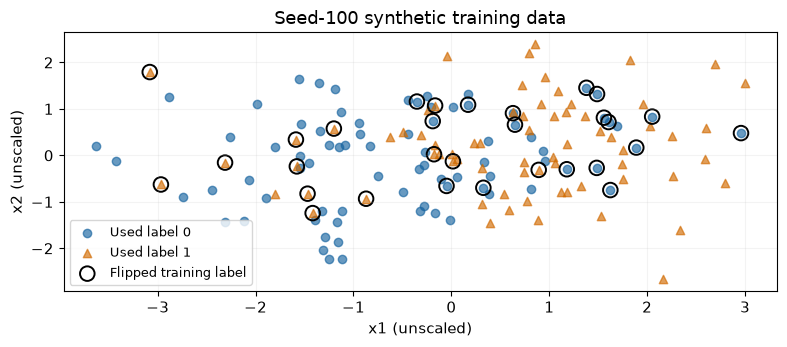

In [8]:
from data_shapley.data import make_data_rngs, generate_gaussian_split, corrupt_training_labels
rngs, _ = make_data_rngs(100)
synthetic = generate_gaussian_split(rngs['synthetic_train'], rngs['synthetic_validation'], rngs['synthetic_test'])
noise = corrupt_training_labels(synthetic.train, 30, (0, 1), rngs['synthetic_noise'])
assert [len(p.y) for p in (synthetic.train, synthetic.validation, synthetic.test)] == [150, 90, 1000]
assert int(noise.corruption_mask.sum()) == 30

table(['Partition', 'Points', 'Flipped labels'], [['Train', 150, 30], ['Validation', 90, 0], ['Test', 1000, 0]])
fig, ax = plt.subplots()
for label, marker, color in [(0, 'o', '#1764a0'), (1, '^', '#d16a00')]:
    keep = noise.training.y == label
    ax.scatter(synthetic.train.X[keep, 0], synthetic.train.X[keep, 1], marker=marker,
               color=color, alpha=.65, label=f'Used label {label}')
flipped = noise.corruption_mask
ax.scatter(synthetic.train.X[flipped, 0], synthetic.train.X[flipped, 1], s=110,
           facecolors='none', edgecolors='black', linewidths=1.4, label='Flipped training label')
ax.set(xlabel='x1 (unscaled)', ylabel='x2 (unscaled)', title='Seed-100 synthetic training data')
ax.legend(fontsize=9)
ax.grid(alpha=.15)
fig.tight_layout()
plt.show()

## Versions
Library versions and random streams used for this run.

In [9]:
table(['Setting', 'Value'], [
    ['Python', sys.version.split()[0]], ['NumPy', np.__version__],
    ['Data preparation', 'make_data_rngs(100)'],
    ['Clean convergence', 'SeedSequence(100, spawn_key=(20, s)), s=0,1'],
    ['Evaluator comparisons', 'SeedSequence(100, spawn_key=(21, ci)), ci=0,1,2'],
    ['Ranking ties', 'SeedSequence(100, spawn_key=(9, ci))'],
    ['Saved study records', 'Run seeds 100-109']])

Setting,Value
Python,3.13.18
NumPy,2.5.3
Data preparation,make_data_rngs(100)
Clean convergence,"SeedSequence(100, spawn_key=(20, s)), s=0,1"
Evaluator comparisons,"SeedSequence(100, spawn_key=(21, ci)), ci=0,1,2"
Ranking ties,"SeedSequence(100, spawn_key=(9, ci))"
Saved study records,Run seeds 100-109
